In [1]:
import json

with open("population.json", "r", encoding="utf-8") as file:
    data = json.load(file)

print(f"Number of records: {len(data)}")
data[0]

Number of records: 152361


{'id': 1000000,
 'demographics': {'age': 88.89568973615539,
  'household_income_band': '< 35k',
  'eyecolor': 'brown'},
 'name': 'Edna Phelps',
 'last_measurements': {'weight': 67.12244970473641, 'temperature': 37.45}}

In [2]:
import numpy as np

ages = np.array([
    person["demographics"]["age"]
    for person in data
])

print(f"Mean age: {np.mean(ages):.2f}")
print(f"Standard deviation: {np.std(ages, ddof=0):.2f}")
print(f"Minimum age: {np.min(ages):.2f}")
print(f"Maximum age: {np.max(ages):.2f}")

Mean age: 39.51
Standard deviation: 24.15
Minimum age: 0.00
Maximum age: 99.99


Largest drop at age: 70
Count before: 1922
Count after: 462


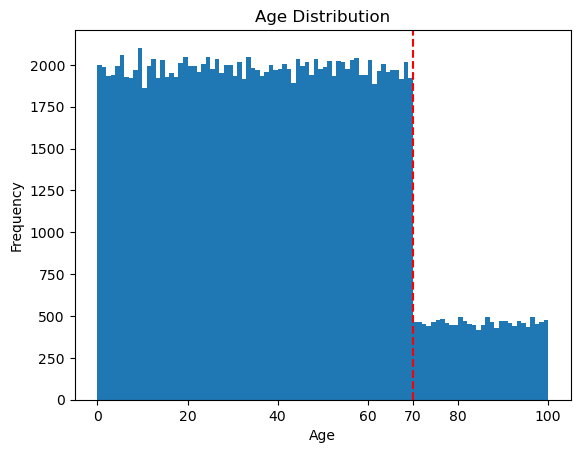

In [8]:
import matplotlib.pyplot as plt

bins = np.arange(np.floor(ages.min()), np.ceil(ages.max()) + 1, 1)

counts, edges = np.histogram(ages, bins=bins)

changes = np.diff(counts)
index = np.argmin(changes)

print(f"Largest drop at age: {edges[index + 1]:.0f}")
print(f"Count before: {counts[index]}")
print(f"Count after: {counts[index + 1]}")


plt.hist(ages, bins=bins)
plt.axvline(x=70, color="red", linestyle="--")
plt.xticks([0, 20, 40, 60, 70, 80, 100])

plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution")
plt.show()

In [9]:
weights = np.array([
    person["last_measurements"]["weight"]
    for person in data
])

print(f"Mean weight: {np.mean(weights):.2f}")
print(f"Standard deviation: {np.std(weights, ddof=0):.2f}")
print(f"Minimum weight: {np.min(weights):.2f}")
print(f"Maximum weight: {np.max(weights):.2f}")

Mean weight: 60.88
Standard deviation: 18.41
Minimum weight: 3.38
Maximum weight: 100.44


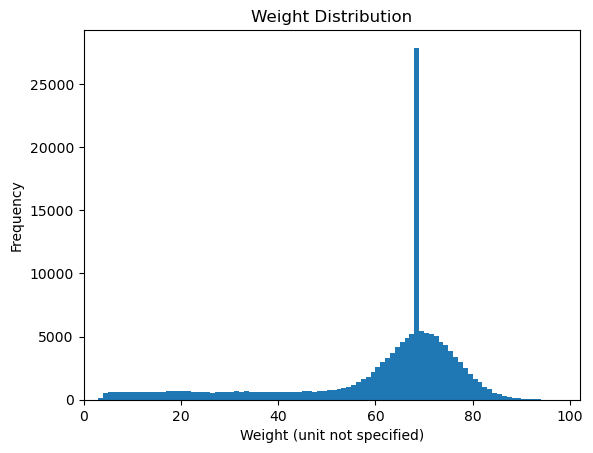

In [15]:
plt.hist(weights, bins=102, range=(0, 102))
plt.xlim(0, 102)
plt.xlabel("Weight (unit not specifgied)")
plt.ylabel("Frequency")
plt.title("Weight Distribution")
plt.show()

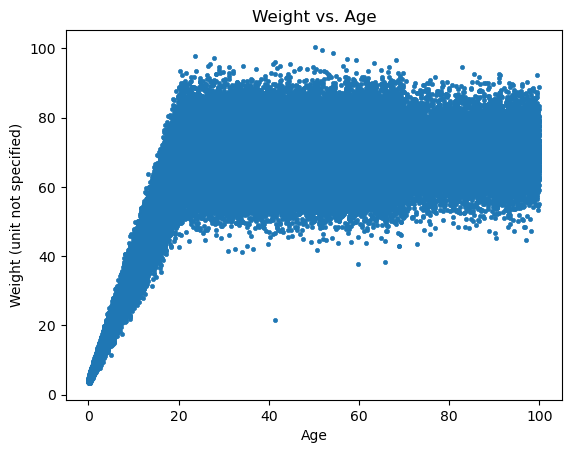

In [19]:
plt.scatter(ages, weights, s=9, linewidths=0.5)
plt.xlabel("Age")
plt.ylabel("Weight (unit not specified)")
plt.title("Weight vs. Age")
plt.show()

In [20]:
unusual_records = [
    person
    for person in data
    if 35 <= person["demographics"]["age"] <= 50
    and person["last_measurements"]["weight"] < 30
]

print(f"Matching records: {len(unusual_records)}")

for person in unusual_records:
    print(
        f"Name: {person['name']}, "
        f"Age: {person['demographics']['age']:.2f}, "
        f"Weight: {person['last_measurements']['weight']:.2f}"
    )

Matching records: 1
Name: Anthony Freeman, Age: 41.30, Weight: 21.70
